# MNIST: multi-seed runs for revision 2

Runs every MNIST experiment in the revised paper: 25 main runs (5 algorithms × 5 seeds, 25 rounds) and 20 short sweep runs (10 rounds). Each run saves a small JSON log in
a local `results` folder. The last cell packs them into **`results_mnist.zip`**; send that file
back in the chat.

The three dataset notebooks (01 MNIST, 02 Fashion-MNIST, 03 CIFAR-10) are independent, so you
can run them one after another or at the same time.

**Needs:** a GPU runtime, plus PyTorch, torchvision, SciPy and matplotlib (all preinstalled on
Colab). The first cells write the shared code (`federated_core.py`, `run_experiments.py`, unit
tests) next to the notebook. Each stage prints an estimate of the time left after its first run.
If you rerun a cell in the same session, runs that already finished are skipped. The `results`
folder only lives as long as the session, though: on Colab, download the zip before the runtime
shuts down.

## 1. Setup

In [1]:
import os, sys, glob, zipfile
RESULTS = 'results'          # one JSON log per run is saved here
os.makedirs(RESULTS, exist_ok=True)
os.makedirs('tests', exist_ok=True)
print('results folder:', os.path.abspath(RESULTS))
print('python:', sys.executable)

results folder: /content/results
python: /usr/bin/python3


## 2. Write the shared code to disk
`federated_core.py` v1.1: the original implementation plus opt-in logging, FedNova-M and the FedMA-lite fix. With default arguments it behaves exactly as v1.0.

In [2]:
%%writefile federated_core.py
"""
federated_core.py
==================
Shared building blocks for the experiments in "Does the Aggregation Rule
Matter? A Controlled Comparison of Two-Tier and Hierarchical Federated
Learning under Non-IID Data" (Mogili Pranav et al.), used by the three
single-seed notebooks (CIFAR10_1_2, mnist_1_2, fmnist_1_2) and by the
multi-seed runner run_experiments.py.

Version 1.1 (revision 2). Additions over v1.0, all opt-in so that the default
arguments reproduce v1.0 exactly:
  * run_federated_experiment(..., log_clients=True) records, per round, each
    client's local step count tau_k and the L2 norm of its update
    ||w_k - w_global||, plus FedMA-lite matching statistics.
  * algorithm="FedNova-M": FedNova with the momentum-corrected normaliser
    ||a_k||_1 of Wang et al. (2020) instead of tau_k (v1.0's "FedNova"
    normalises by tau_k, the plain-SGD form, although local training uses
    momentum 0.9).
  * fedma_next_layer="conv2.weight": FedMA-lite also applies each client's
    conv1 channel permutation to the input channels of the next layer, so
    matched channels stay connected to the weights trained on them. v1.0
    permuted conv1 only (fedma_next_layer=None reproduces that).
  * local_momentum argument (default 0.9, as in v1.0) for the plain-SGD
    ablation.

This module implements, from scratch on top of PyTorch:
  * Dirichlet(alpha) non-IID label partitioning across clients (Fig. 3/5/6 in
    the paper).
  * Heterogeneous per-client "compute speed" multipliers (0.25x-4x, Sec III-A)
    used only to simulate per-round wall-clock latency.
  * Local client training, including the FedProx proximal term.
  * Five aggregation strategies: FedAvg, FedProx, FedNova, HierFAVG (a real
    two-level hierarchical aggregation: client -> edge cluster -> global),
    and a simplified "FedMA-lite" that performs Hungarian-matching-based
    neuron alignment on the first convolutional layer before averaging
    (see the note in fedma_lite_aggregate for exactly what is simplified
    relative to the full Bayesian non-parametric matching in Wang et al. 2020).
  * A generic experiment runner (`run_federated_experiment`) that trains any
    of the five algorithms for a configurable number of communication
    rounds and returns a pandas-friendly history of accuracy, WAN-bound
    communication (MB), and simulated per-round latency (s).
  * Plotting helpers that reproduce the paper's figures (class-distribution
    heatmap, convergence curves, final-accuracy bar chart, communication
    bar chart).

Nothing in this file downloads data -- each notebook is responsible for
loading its own dataset (MNIST / Fashion-MNIST / CIFAR-10) via torchvision
and building per-client Subset/DataLoader objects from the index lists
returned by `dirichlet_partition`.
"""

import copy
import time
import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import DataLoader

try:
    from scipy.optimize import linear_sum_assignment
    _HAS_SCIPY = True
except Exception:
    _HAS_SCIPY = False


# ---------------------------------------------------------------------------
# Reproducibility
# ---------------------------------------------------------------------------
def set_seed(seed: int = 42):
    """Seed python-level, numpy and torch RNGs (CPU + CUDA) for reproducibility."""
    import random
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


# ---------------------------------------------------------------------------
# Non-IID partitioning (paper Sec III-A / Fig. 3, 5, 6)
# ---------------------------------------------------------------------------
def dirichlet_partition(labels, num_clients: int, alpha: float, num_classes: int, seed: int = 42):
    """
    Split sample indices into `num_clients` non-IID shards.

    For each class c, draw a Dirichlet(alpha, ..., alpha) proportion vector
    over the clients and assign that class's samples to clients according
    to those proportions. Small alpha (e.g. 0.1) => high label skew (most
    clients dominated by 1-2 classes); large alpha (e.g. 1.0+) => close to IID.

    Returns
    -------
    list[list[int]] : client_indices[i] is the list of dataset indices
    assigned to client i.
    """
    rng = np.random.default_rng(seed)
    labels = np.asarray(labels)
    client_indices = [[] for _ in range(num_clients)]

    for c in range(num_classes):
        idx_c = np.where(labels == c)[0]
        rng.shuffle(idx_c)
        proportions = rng.dirichlet(alpha * np.ones(num_clients))
        split_points = (np.cumsum(proportions) * len(idx_c)).astype(int)[:-1]
        splits = np.split(idx_c, split_points)
        for i, s in enumerate(splits):
            client_indices[i].extend(s.tolist())

    for i in range(num_clients):
        rng.shuffle(client_indices[i])
        # Guarantee every client has at least 1 sample so DataLoader never
        # receives an empty dataset (can happen with very small alpha and
        # a small total dataset size).
        if len(client_indices[i]) == 0:
            donor = int(np.argmax([len(x) for x in client_indices]))
            if len(client_indices[donor]) > 1:
                moved = client_indices[donor].pop()
                client_indices[i].append(moved)

    return client_indices


def get_client_speed_multipliers(num_clients: int, low: float = 0.25, high: float = 4.0, seed: int = 42):
    """Uniform(low, high) per-client relative compute-speed multipliers (paper Sec III-A)."""
    rng = np.random.default_rng(seed)
    return rng.uniform(low, high, size=num_clients)


def make_edge_clusters(num_clients: int, num_clusters: int, seed: int = 42):
    """
    Randomly assign each client to one of `num_clusters` edge servers for
    HierFAVG (paper Sec I-E / Fig. 2). Returns a list `cluster_of[i]` giving
    the cluster id of client i, and `clusters[k]` giving the list of client
    ids in cluster k.
    """
    rng = np.random.default_rng(seed)
    cluster_of = rng.integers(0, num_clusters, size=num_clients)
    clusters = [np.where(cluster_of == k)[0].tolist() for k in range(num_clusters)]
    # Make sure no cluster is empty.
    empty = [k for k, c in enumerate(clusters) if len(c) == 0]
    for k in empty:
        donor = int(np.argmax([len(c) for c in clusters]))
        moved = clusters[donor].pop()
        clusters[k].append(moved)
        cluster_of[moved] = k
    return cluster_of.tolist(), clusters


# ---------------------------------------------------------------------------
# Model (de)serialization helpers
# ---------------------------------------------------------------------------
def clone_state(state_dict):
    return {k: v.clone() for k, v in state_dict.items()}


def model_size_mb(model: nn.Module) -> float:
    """Size of one full copy of the model's parameters, in megabytes (float32)."""
    total_bytes = sum(p.numel() * 4 for p in model.parameters())
    return total_bytes / (1024 ** 2)


# ---------------------------------------------------------------------------
# Local training (client update)
# ---------------------------------------------------------------------------
def local_train(model: nn.Module, dataloader: DataLoader, epochs: int, lr: float,
                 device, mu: float = 0.0, global_state=None, momentum: float = 0.9):
    """
    Train `model` locally for `epochs` epochs of SGD.

    If mu > 0 and `global_state` is given, adds the FedProx proximal term
    (mu/2) * ||w - w_global||^2 to the loss (paper Sec II-B).

    Returns
    -------
    (state_dict, num_local_steps) : the updated local weights and the
    number of SGD steps taken (needed by FedNova's step-count normalisation).
    """
    model.train()
    optimizer = torch.optim.SGD(model.parameters(), lr=lr, momentum=momentum)
    criterion = nn.CrossEntropyLoss()

    global_params = None
    if mu > 0 and global_state is not None:
        global_params = {k: v.clone().to(device) for k, v in global_state.items()
                          if k in dict(model.named_parameters())}

    steps = 0
    for _ in range(epochs):
        for xb, yb in dataloader:
            xb, yb = xb.to(device), yb.to(device)
            optimizer.zero_grad()
            out = model(xb)
            loss = criterion(out, yb)
            if mu > 0 and global_params is not None:
                prox = torch.zeros((), device=device)
                for name, param in model.named_parameters():
                    if name in global_params:
                        prox = prox + ((param - global_params[name]) ** 2).sum()
                loss = loss + (mu / 2.0) * prox
            loss.backward()
            optimizer.step()
            steps += 1

    return clone_state(model.state_dict()), max(steps, 1)


# ---------------------------------------------------------------------------
# Aggregation strategies
# ---------------------------------------------------------------------------
def fedavg_aggregate(client_states, client_weights):
    """Data-volume-weighted average of a list of state_dicts (paper Sec I-C)."""
    total = float(sum(client_weights))
    keys = client_states[0].keys()
    new_state = {}
    for k in keys:
        ref = client_states[0][k]
        if not torch.is_floating_point(ref):
            # e.g. BatchNorm's num_batches_tracked (integer buffer): just
            # take the first client's value, it is not meaningfully
            # "averaged" across clients.
            new_state[k] = ref.clone()
            continue
        acc = torch.zeros_like(ref, dtype=torch.float32)
        for cs, w in zip(client_states, client_weights):
            acc += cs[k].float() * (w / total)
        new_state[k] = acc.to(ref.dtype)
    return new_state


def momentum_normaliser(tau: int, rho: float) -> float:
    """||a_k||_1 for tau local steps of SGD with momentum rho (Wang et al. 2020):
    a_k[j] = (1 - rho^(tau-j+1)) / (1 - rho), summed over j = 1..tau."""
    if rho <= 0:
        return float(tau)
    return (tau - rho * (1 - rho ** tau) / (1 - rho)) / (1 - rho)


def fednova_aggregate(global_state, client_states, client_weights, client_steps,
                      momentum: float = 0.0):
    """
    FedNova (Wang et al. 2020, paper Sec II-B): normalise each client's
    cumulative update direction by its own local step count tau_i before
    combining, removing the systematic bias FedAvg introduces when clients
    take different numbers of local steps. An effective global step size
    tau_eff (the data-weighted average step count) is then applied to the
    combined normalised direction.

    momentum=0.0 (default, = v1.0): normalise by tau_k (plain-SGD FedNova).
    momentum=rho>0: normalise by ||a_k||_1 = momentum_normaliser(tau_k, rho),
    the form Wang et al. give for local SGD with momentum rho.
    """
    total = float(sum(client_weights))
    norms = [momentum_normaliser(max(s, 1), momentum) for s in client_steps]
    tau_eff = sum((w / total) * a for w, a in zip(client_weights, norms))

    new_state = {}
    for k in global_state.keys():
        ref = global_state[k]
        if not torch.is_floating_point(ref):
            new_state[k] = client_states[0][k].clone()
            continue
        delta_sum = torch.zeros_like(ref, dtype=torch.float32)
        for cs, w, a in zip(client_states, client_weights, norms):
            delta = (cs[k].float() - ref.float()) / a
            delta_sum += (w / total) * delta
        new_state[k] = (ref.float() + tau_eff * delta_sum).to(ref.dtype)
    return new_state


def hierfavg_aggregate(client_states, client_weights, cluster_of, num_clusters):
    """
    HierFAVG (Liu et al. 2020, paper Sec I-E / Fig. 2): first FedAvg within
    each edge cluster (client -> edge), then FedAvg the resulting cluster
    models weighted by each cluster's total data volume (edge -> global).

    Mathematically this reduces to the same weighted global average as
    flat FedAvg (both are weighted means over the same data), but only the
    K cluster models (not the N client models) cross the WAN link to the
    global server -- that's the communication saving the paper reports.
    Returns (new_global_state, cluster_states) so the caller can account
    for edge-vs-WAN communication separately.
    """
    cluster_states = []
    cluster_weights = []
    for k in range(num_clusters):
        member_idx = [i for i, c in enumerate(cluster_of) if c == k]
        if not member_idx:
            continue
        states_k = [client_states[i] for i in member_idx]
        weights_k = [client_weights[i] for i in member_idx]
        cluster_states.append(fedavg_aggregate(states_k, weights_k))
        cluster_weights.append(sum(weights_k))

    new_global = fedavg_aggregate(cluster_states, cluster_weights)
    return new_global, cluster_states, cluster_weights


def fedma_lite_aggregate(client_states, client_weights, match_layer: str,
                         next_layer: str = None, stats: dict = None):
    """
    Simplified single-layer FedMA ("FedMA-lite").

    The full algorithm of Wang et al. (2020) matches and averages neurons
    layer-by-layer, using the matched (and frozen) earlier layers to
    re-run local training before matching the next layer -- which requires
    re-invoking client-side training mid-aggregation. That round-trip is
    expensive to script generically for an arbitrary model, so here we
    approximate the *first* convolutional layer's channel matching (the
    part of the network the paper's Fig-driven discussion centers on --
    "matches neurons before averaging" / "preserve model structure") with
    a single Hungarian-assignment step, then FedAvg everything else
    (including all later layers) as usual. This captures FedMA's core idea
    (permutation-invariant averaging instead of naive coordinate-wise
    averaging) without the full iterative matched-freeze-retrain loop, and
    is the "simplified" method referenced in the notebook's markdown.

    match_layer: state_dict key of a Conv2d weight tensor of shape
    (out_channels, in_channels, kH, kW) to align across clients before
    averaging. The reference is client 0's layer; every other client's
    output channels are permuted onto it by maximum total cosine similarity
    (Hungarian algorithm), together with the layer's bias.

    next_layer: optional state_dict key of the following Conv2d weight. If
    given, each client's permutation is also applied to that layer's input
    channels (dim 1) before it is averaged, so the network each client
    contributes is functionally unchanged by the permutation. If None
    (v1.0 behaviour) the next layer is averaged unpermuted.

    stats: optional dict; if given, stats["moved"] receives, for each
    client 1..N-1, the number of output channels whose index changed.
    """
    if not _HAS_SCIPY:
        # Fall back to plain FedAvg if scipy is unavailable.
        return fedavg_aggregate(client_states, client_weights)

    total = float(sum(client_weights))
    ref_w = client_states[0][match_layer].float()
    out_ch = ref_w.shape[0]
    matched_weights = [ref_w]
    matched_biases = None
    bias_key = match_layer.replace("weight", "bias")
    has_bias = bias_key in client_states[0]
    if has_bias:
        matched_biases = [client_states[0][bias_key].float()]

    matched_next = None
    if next_layer is not None:
        assert client_states[0][next_layer].dim() == 4 and \
            client_states[0][next_layer].shape[1] == out_ch, \
            "next_layer must be a Conv2d weight whose in_channels equal match_layer's out_channels"
        matched_next = [client_states[0][next_layer].float()]
    moved = []

    flat_ref = ref_w.reshape(out_ch, -1)
    for cs in client_states[1:]:
        w = cs[match_layer].float()
        flat_w = w.reshape(out_ch, -1)
        # cosine-similarity cost matrix between reference channels and this
        # client's channels -> Hungarian algorithm finds the best 1-1
        # permutation of this client's output channels onto the reference.
        ref_n = flat_ref / (flat_ref.norm(dim=1, keepdim=True) + 1e-8)
        w_n = flat_w / (flat_w.norm(dim=1, keepdim=True) + 1e-8)
        sim = (ref_n @ w_n.T).cpu().numpy()
        row_ind, col_ind = linear_sum_assignment(-sim)  # maximize similarity
        perm = np.argsort(row_ind)  # ensure rows are 0..out_ch-1 in order
        col_ind = col_ind[perm]
        matched_weights.append(w[col_ind])
        if has_bias:
            matched_biases.append(cs[bias_key].float()[col_ind])
        if matched_next is not None:
            matched_next.append(cs[next_layer].float()[:, col_ind])
        moved.append(int((col_ind != np.arange(out_ch)).sum()))

    weighted_sum = torch.zeros_like(ref_w)
    for mw, cw in zip(matched_weights, client_weights):
        weighted_sum += mw * (cw / total)

    new_state = fedavg_aggregate(client_states, client_weights)  # everything else, plain FedAvg
    new_state[match_layer] = weighted_sum.to(client_states[0][match_layer].dtype)
    if has_bias:
        weighted_bias = torch.zeros_like(matched_biases[0])
        for mb, cw in zip(matched_biases, client_weights):
            weighted_bias += mb * (cw / total)
        new_state[bias_key] = weighted_bias.to(client_states[0][bias_key].dtype)
    if matched_next is not None:
        weighted_next = torch.zeros_like(matched_next[0])
        for mn, cw in zip(matched_next, client_weights):
            weighted_next += mn * (cw / total)
        new_state[next_layer] = weighted_next.to(client_states[0][next_layer].dtype)
    if stats is not None:
        stats["moved"] = moved
    return new_state


def update_norm(client_state, global_state) -> float:
    """L2 norm of client_state - global_state over all floating-point entries."""
    sq = 0.0
    for k, g in global_state.items():
        if torch.is_floating_point(g):
            sq += float(((client_state[k].float() - g.float()) ** 2).sum())
    return sq ** 0.5


# ---------------------------------------------------------------------------
# Evaluation
# ---------------------------------------------------------------------------
@torch.no_grad()
def evaluate(model: nn.Module, dataloader: DataLoader, device) -> float:
    model.eval()
    correct, total = 0, 0
    for xb, yb in dataloader:
        xb, yb = xb.to(device), yb.to(device)
        out = model(xb)
        pred = out.argmax(dim=1)
        correct += (pred == yb).sum().item()
        total += yb.size(0)
    return 100.0 * correct / max(total, 1)


# ---------------------------------------------------------------------------
# Generic federated experiment runner
# ---------------------------------------------------------------------------
def run_federated_experiment(
    algorithm: str,
    model_fn,
    client_loaders,
    client_sizes,
    test_loader,
    device,
    rounds: int,
    local_epochs: int,
    lr: float,
    mu: float = 0.01,
    cluster_of=None,
    num_clusters=None,
    fedma_match_layer=None,
    speed_multipliers=None,
    base_latency_s: float = 0.02,
    eval_every: int = 1,
    verbose: bool = True,
    local_momentum: float = 0.9,
    fedma_next_layer=None,
    log_clients: bool = False,
):
    """
    Run one federated learning algorithm end-to-end and return a history dict.

    algorithm: one of {"FedAvg", "FedProx", "FedNova", "FedNova-M", "HierFAVG", "FedMA"}
        ("FedNova-M" = FedNova with the momentum-corrected normaliser)
    model_fn: zero-arg callable returning a freshly-initialised model
    client_loaders: list[DataLoader], one per client
    client_sizes: list[int], number of samples per client (aggregation weights)
    cluster_of / num_clusters: required for HierFAVG
    fedma_match_layer: required for FedMA (state_dict key of a Conv2d weight)
    speed_multipliers: optional list[float]; per-round latency is simulated as
        base_latency_s / speed_multiplier, and the round's latency is the max
        (slowest straggler) across participating clients, plus a small
        constant for the aggregation step. Speed multipliers do NOT change
        local training: every client runs `local_epochs` full epochs.
    local_momentum: momentum of the clients' local SGD (v1.0 used 0.9).
    fedma_next_layer: see fedma_lite_aggregate (None = v1.0 behaviour).
    log_clients: if True, the history also contains "client_steps",
        "update_norms" (per round, one float per client) and, for FedMA,
        "fedma_moved" (per round, channels moved per client 1..N-1).

    Returns
    -------
    dict with keys: "round", "accuracy", "wan_comm_mb", "latency_s"
    (all lists, one entry per evaluated round), plus "best_accuracy",
    "convergence_round" (first round the best accuracy was reached),
    "total_wan_comm_mb", and "avg_latency_s".
    """
    assert algorithm in {"FedAvg", "FedProx", "FedNova", "FedNova-M", "HierFAVG", "FedMA"}
    if algorithm == "HierFAVG":
        assert cluster_of is not None and num_clusters is not None
    if algorithm == "FedMA":
        assert fedma_match_layer is not None

    global_model = model_fn().to(device)
    global_state = clone_state(global_model.state_dict())
    n_clients = len(client_loaders)
    per_client_mb = model_size_mb(global_model)

    history = {"round": [], "accuracy": [], "wan_comm_mb": [], "latency_s": []}
    if log_clients:
        history.update({"client_steps": None, "update_norms": [], "fedma_moved": []})
    best_acc, best_round = 0.0, 0
    cumulative_mb = 0.0

    for r in range(1, rounds + 1):
        client_states, client_steps, round_latencies = [], [], []

        for i in range(n_clients):
            local_model = model_fn().to(device)
            local_model.load_state_dict(global_state)
            local_mu = mu if algorithm == "FedProx" else 0.0

            t0 = time.time()
            state_i, steps_i = local_train(
                local_model, client_loaders[i], epochs=local_epochs, lr=lr,
                device=device, mu=local_mu, global_state=global_state,
                momentum=local_momentum,
            )
            sim_time = base_latency_s
            if speed_multipliers is not None:
                sim_time = base_latency_s / max(speed_multipliers[i], 1e-3)
            round_latencies.append(sim_time)

            client_states.append(state_i)
            client_steps.append(steps_i)

        if log_clients:
            if history["client_steps"] is None:
                history["client_steps"] = list(client_steps)
            history["update_norms"].append([update_norm(cs, global_state) for cs in client_states])

        # --- Aggregation ---
        if algorithm in ("FedAvg", "FedProx"):
            global_state = fedavg_aggregate(client_states, client_sizes)
            wan_mb_this_round = n_clients * per_client_mb  # N updates to server
        elif algorithm == "FedNova":
            global_state = fednova_aggregate(global_state, client_states, client_sizes, client_steps)
            wan_mb_this_round = n_clients * per_client_mb
        elif algorithm == "FedNova-M":
            global_state = fednova_aggregate(global_state, client_states, client_sizes, client_steps,
                                             momentum=local_momentum)
            wan_mb_this_round = n_clients * per_client_mb
        elif algorithm == "HierFAVG":
            global_state, cluster_states, cluster_weights = hierfavg_aggregate(
                client_states, client_sizes, cluster_of, num_clusters
            )
            wan_mb_this_round = len(cluster_states) * per_client_mb  # only K cluster reports cross the WAN
        elif algorithm == "FedMA":
            fedma_stats = {}
            global_state = fedma_lite_aggregate(client_states, client_sizes, fedma_match_layer,
                                                next_layer=fedma_next_layer, stats=fedma_stats)
            if log_clients:
                history["fedma_moved"].append(fedma_stats.get("moved", []))
            wan_mb_this_round = n_clients * per_client_mb

        cumulative_mb += wan_mb_this_round
        round_latency = max(round_latencies) + 0.05  # + fixed aggregation overhead

        if r % eval_every == 0 or r == rounds:
            global_model.load_state_dict(global_state)
            acc = evaluate(global_model, test_loader, device)
            history["round"].append(r)
            history["accuracy"].append(acc)
            history["wan_comm_mb"].append(cumulative_mb)
            history["latency_s"].append(round_latency)
            if acc > best_acc:
                best_acc, best_round = acc, r
            if verbose:
                print(f"[{algorithm}] round {r:3d}/{rounds} | acc={acc:5.2f}% | "
                      f"cum. WAN comm={cumulative_mb:8.1f} MB | latency={round_latency:.2f} s")

    return {
        **history,
        "best_accuracy": best_acc,
        "convergence_round": best_round,
        "total_wan_comm_mb": cumulative_mb,
        "avg_latency_s": float(np.mean(history["latency_s"])) if history["latency_s"] else 0.0,
        "algorithm": algorithm,
    }


# ---------------------------------------------------------------------------
# Plotting helpers (mirrors the paper's Fig. 3/5/6, Fig. 7/8, Fig. 9/10)
# ---------------------------------------------------------------------------
def plot_class_distribution(labels, client_indices, class_names, title, ax=None):
    import matplotlib.pyplot as plt
    labels = np.asarray(labels)
    n_clients = len(client_indices)
    n_classes = len(class_names)
    heat = np.zeros((n_clients, n_classes))
    for i, idx in enumerate(client_indices):
        if len(idx) == 0:
            continue
        cls, counts = np.unique(labels[idx], return_counts=True)
        heat[i, cls] = counts / counts.sum()

    own_ax = ax is None
    if own_ax:
        fig, ax = plt.subplots(figsize=(max(6, n_clients * 0.35), 4))
    im = ax.imshow(heat.T, aspect="auto", cmap="viridis", vmin=0, vmax=1)
    ax.set_yticks(range(n_classes))
    ax.set_yticklabels(class_names)
    ax.set_xticks(range(n_clients))
    ax.set_xticklabels([f"C{i}" for i in range(n_clients)], rotation=90, fontsize=6)
    ax.set_xlabel("Client index")
    ax.set_ylabel("Class")
    ax.set_title(title)
    if own_ax:
        fig.colorbar(im, ax=ax, label="Proportion of client samples")
        fig.tight_layout()
        return fig, ax
    return ax


def plot_convergence(histories: dict, title: str):
    """histories: {algorithm_name: history_dict from run_federated_experiment}"""
    import matplotlib.pyplot as plt
    fig, ax = plt.subplots(figsize=(7, 5))
    for name, h in histories.items():
        ax.plot(h["round"], h["accuracy"], marker="o", markersize=3, label=name)
    ax.set_xlabel("Communication round")
    ax.set_ylabel("Test accuracy (%)")
    ax.set_title(title)
    ax.legend()
    fig.tight_layout()
    return fig, ax


def plot_final_accuracy_bar(histories: dict, title: str):
    import matplotlib.pyplot as plt
    names = list(histories.keys())
    accs = [histories[n]["accuracy"][-1] for n in names]
    fig, ax = plt.subplots(figsize=(6, 4))
    ax.bar(names, accs, color="tab:blue")
    ax.set_ylabel("Final test accuracy (%)")
    ax.set_title(title)
    for i, a in enumerate(accs):
        ax.text(i, a + 0.5, f"{a:.1f}", ha="center")
    fig.tight_layout()
    return fig, ax


def plot_communication_bar(histories: dict, title: str):
    import matplotlib.pyplot as plt
    names = list(histories.keys())
    comms = [histories[n]["wan_comm_mb"][-1] for n in names]
    fig, ax = plt.subplots(figsize=(6, 4))
    ax.bar(names, comms, color="tab:orange")
    ax.set_ylabel("Total WAN-bound communication (MB)")
    ax.set_title(title)
    for i, c in enumerate(comms):
        ax.text(i, c + max(comms) * 0.01, f"{c:.0f}", ha="center")
    fig.tight_layout()
    return fig, ax


def summary_table(histories: dict):
    """Return a list of dict rows suitable for pandas.DataFrame(...), matching
    the paper's Table VI/VII/VIII columns."""
    rows = []
    for name, h in histories.items():
        rows.append({
            "Model": name,
            "Accuracy (%)": round(h["accuracy"][-1], 1),
            "Communication (MB)": round(h["wan_comm_mb"][-1], 1),
            "Convergence round": h["convergence_round"],
            "Latency (s/round)": round(h["avg_latency_s"], 2),
        })
    return rows

Writing federated_core.py


In [3]:
%%writefile run_experiments.py
"""
run_experiments.py -- multi-seed runner for the revision-2 experiments.

Runs every configuration reported in the paper and writes one JSON file per
run. Finished runs are skipped, so the script can be stopped and restarted at
any time without repeating work.

Stages
------
  main      3 datasets x 5 algorithms x seeds, alpha=0.1, 25 rounds
            (Table VI, Figs. 4-5; FedNova runs also feed Fig. 6)
  sweep     3 datasets x {FedAvg, FedNova} x alpha in {0.5, 1.0} x seeds,
            10 rounds (Table VII; the alpha=0.1 column is read from round 10
            of the main runs, which use identical settings)
  ablation  Fashion-MNIST and CIFAR-10 x {FedNova-M, FedAvg-SGD, FedNova-SGD}
            x ablation seeds, 25 rounds (Table VIII)
  all       main, then sweep, then ablation

Protocol (identical to the single-seed notebooks)
-------------------------------------------------
20 clients, Dirichlet(alpha) label partition, every client runs E=5 full
epochs per round (batch 32, SGD lr 0.01, momentum 0.9 unless stated), all
clients participate every round, FedProx mu=0.01, HierFAVG with 4 random edge
clusters and one edge aggregation per global round, FedMA-lite matching conv1
and propagating the permutation to conv2 (federated_core v1.1). For each seed,
the partition, speed multipliers, cluster assignment, model initialisation and
minibatch order all derive from that seed; every algorithm starts from the
same initial model.

The only change from the notebooks is data loading: each dataset is
normalised once and kept on the GPU, and minibatches are drawn by index
(same batch size, reshuffled every epoch, last partial batch kept). This
removes the per-sample PIL/DataLoader overhead without changing what is
computed.

Usage
-----
  python tests/test_core.py                       # unit tests (seconds)
  python run_experiments.py --smoke               # every code path, tiny (minutes)
  python run_experiments.py --stage main          # then sweep, ablation
  python run_experiments.py --stage all --out results
"""
import argparse
import json
import math
import os
import platform
import sys
import time

import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F

sys.path.insert(0, os.path.dirname(os.path.abspath(__file__)))
import federated_core as fc  # noqa: E402

# ---------------------------------------------------------------------------
# Configuration
# ---------------------------------------------------------------------------
NUM_CLIENTS = 20
ROUNDS = 25
LOCAL_EPOCHS = 5
BATCH_SIZE = 32
LR = 0.01
MU_FEDPROX = 0.01
NUM_CLUSTERS = 4
SPEED_LOW, SPEED_HIGH = 0.25, 4.0      # only used for the simulated latency
ALPHA_MAIN = 0.1
SWEEP_ALPHAS = [0.5, 1.0]
SWEEP_ROUNDS = 10
DEFAULT_SEEDS = [42, 43, 44, 45, 46]
DEFAULT_ABLATION_SEEDS = [42, 43, 44]

DATASETS = ["MNIST", "Fashion-MNIST", "CIFAR-10"]
MAIN_ALGOS = ["FedAvg", "FedProx", "FedNova", "HierFAVG", "FedMA"]
SWEEP_ALGOS = ["FedAvg", "FedNova"]
ABLATION_DATASETS = ["Fashion-MNIST", "CIFAR-10"]
# reported name -> (federated_core algorithm, local SGD momentum)
ABLATIONS = {
    "FedNova-M": ("FedNova-M", 0.9),    # momentum-corrected FedNova normaliser
    "FedAvg-SGD": ("FedAvg", 0.0),      # plain local SGD (no momentum)
    "FedNova-SGD": ("FedNova", 0.0),    # plain SGD: tau_k normaliser is exact
}
FEDMA_MATCH_LAYER = "conv1.weight"
FEDMA_NEXT_LAYER = "conv2.weight"

NORM = {
    "MNIST": ((0.1307,), (0.3081,)),
    "Fashion-MNIST": ((0.2860,), (0.3530,)),
    "CIFAR-10": ((0.4914, 0.4822, 0.4465), (0.2470, 0.2435, 0.2616)),
}
SLUG = {"MNIST": "mnist", "Fashion-MNIST": "fmnist", "CIFAR-10": "cifar10"}


# ---------------------------------------------------------------------------
# Models (copied unchanged from the notebooks)
# ---------------------------------------------------------------------------
class SmallCNN(nn.Module):
    """~52K-parameter 2-layer CNN (MNIST / Fashion-MNIST)."""
    def __init__(self, in_channels=1, num_classes=10):
        super().__init__()
        self.conv1 = nn.Conv2d(in_channels, 8, kernel_size=3, padding=1)
        self.conv2 = nn.Conv2d(8, 16, kernel_size=3, padding=1)
        self.pool = nn.MaxPool2d(2, 2)
        self.fc1 = nn.Linear(16 * 7 * 7, 64)
        self.fc2 = nn.Linear(64, num_classes)

    def forward(self, x):
        x = self.pool(F.relu(self.conv1(x)))   # 28x28 -> 14x14
        x = self.pool(F.relu(self.conv2(x)))   # 14x14 -> 7x7
        x = x.flatten(1)
        x = F.relu(self.fc1(x))
        return self.fc2(x)


class CompactCIFARCNN(nn.Module):
    """156,074-parameter 3-layer CNN (CIFAR-10)."""
    def __init__(self, num_classes=10):
        super().__init__()
        self.conv1 = nn.Conv2d(3, 16, kernel_size=3, padding=1)
        self.conv2 = nn.Conv2d(16, 32, kernel_size=3, padding=1)
        self.conv3 = nn.Conv2d(32, 64, kernel_size=3, padding=1)
        self.pool = nn.MaxPool2d(2, 2)
        self.fc1 = nn.Linear(64 * 4 * 4, 128)
        self.fc2 = nn.Linear(128, num_classes)

    def forward(self, x):
        x = self.pool(F.relu(self.conv1(x)))   # 32x32 -> 16x16
        x = self.pool(F.relu(self.conv2(x)))   # 16x16 -> 8x8
        x = self.pool(F.relu(self.conv3(x)))   # 8x8 -> 4x4
        x = x.flatten(1)
        x = F.relu(self.fc1(x))
        return self.fc2(x)


MODEL_FN = {
    "MNIST": lambda: SmallCNN(in_channels=1, num_classes=10),
    "Fashion-MNIST": lambda: SmallCNN(in_channels=1, num_classes=10),
    "CIFAR-10": lambda: CompactCIFARCNN(num_classes=10),
}


# ---------------------------------------------------------------------------
# Data
# ---------------------------------------------------------------------------
def load_dataset(name, root, device):
    """Return normalised train/test tensors on `device` plus numpy train labels.
    Same values as torchvision ToTensor() followed by Normalize(mean, std)."""
    import torchvision
    cls = {"MNIST": torchvision.datasets.MNIST,
           "Fashion-MNIST": torchvision.datasets.FashionMNIST,
           "CIFAR-10": torchvision.datasets.CIFAR10}[name]
    mean, std = NORM[name]

    def to_tensors(ds):
        x = ds.data if torch.is_tensor(ds.data) else torch.from_numpy(np.asarray(ds.data))
        x = x.unsqueeze(1) if x.dim() == 3 else x.permute(0, 3, 1, 2)   # N,C,H,W
        x = x.float().div(255.0)
        x = (x - torch.tensor(mean).view(1, -1, 1, 1)) / torch.tensor(std).view(1, -1, 1, 1)
        y = torch.as_tensor(ds.targets, dtype=torch.long)
        return x.contiguous().to(device), y.to(device)

    train = cls(root=root, train=True, download=True)
    test = cls(root=root, train=False, download=True)
    xtr, ytr = to_tensors(train)
    xte, yte = to_tensors(test)
    labels = ytr.cpu().numpy()
    return xtr, ytr, xte, yte, labels


class TensorLoader:
    """Iterates over minibatches of (x[idx], y[idx]) for tensors already on
    the device. Equivalent to DataLoader(Subset(ds, idx), batch_size,
    shuffle, drop_last=False): a fresh random order every epoch, last partial
    batch kept, len() = ceil(n / batch_size)."""

    def __init__(self, x, y, indices, batch_size, shuffle):
        self.x, self.y = x, y
        self.idx = torch.as_tensor(np.asarray(indices, dtype=np.int64), device=x.device)
        self.batch_size, self.shuffle = batch_size, shuffle

    def __len__(self):
        return math.ceil(len(self.idx) / self.batch_size)

    def __iter__(self):
        idx = self.idx
        if self.shuffle:
            idx = idx[torch.randperm(len(idx), device=idx.device)]
        for s in range(0, len(idx), self.batch_size):
            b = idx[s:s + self.batch_size]
            yield self.x[b], self.y[b]


# ---------------------------------------------------------------------------
# Jobs
# ---------------------------------------------------------------------------
def make_jobs(stage, seeds, ablation_seeds, datasets, smoke=False):
    """Yield dicts describing single runs, grouped by dataset."""
    jobs = []
    for ds in datasets:
        if smoke:
            for algo in MAIN_ALGOS:
                jobs.append(dict(stage="smoke", ds=ds, name=algo, algo=algo, mom=0.9, alpha=ALPHA_MAIN, seed=42, rounds=2, epochs=1))
            for name, (algo, mom) in ABLATIONS.items():
                jobs.append(dict(stage="smoke", ds=ds, name=name, algo=algo, mom=mom, alpha=ALPHA_MAIN, seed=42, rounds=2, epochs=1))
            jobs.append(dict(stage="smoke", ds=ds, name="FedNova", algo="FedNova", mom=0.9, alpha=0.5, seed=42, rounds=2, epochs=1))
            continue
        if stage in ("main", "all"):
            for seed in seeds:
                for algo in MAIN_ALGOS:
                    jobs.append(dict(stage="main", ds=ds, name=algo, algo=algo, mom=0.9, alpha=ALPHA_MAIN, seed=seed, rounds=ROUNDS, epochs=LOCAL_EPOCHS))
        if stage in ("sweep", "all"):
            for seed in seeds:
                for alpha in SWEEP_ALPHAS:
                    for algo in SWEEP_ALGOS:
                        jobs.append(dict(stage="sweep", ds=ds, name=algo, algo=algo, mom=0.9, alpha=alpha, seed=seed, rounds=SWEEP_ROUNDS, epochs=LOCAL_EPOCHS))
        if stage in ("ablation", "all") and ds in ABLATION_DATASETS:
            for seed in ablation_seeds:
                for name, (algo, mom) in ABLATIONS.items():
                    jobs.append(dict(stage="ablation", ds=ds, name=name, algo=algo, mom=mom, alpha=ALPHA_MAIN, seed=seed, rounds=ROUNDS, epochs=LOCAL_EPOCHS))
    # Stage order: all main runs first, then sweep, then ablation.
    order = {"smoke": 0, "main": 0, "sweep": 1, "ablation": 2}
    jobs.sort(key=lambda j: (order[j["stage"]], datasets.index(j["ds"])))
    return jobs


def out_path(out, job):
    return os.path.join(out, job["stage"], f"{SLUG[job['ds']]}_a{job['alpha']}_{job['name']}_s{job['seed']}.json")


def to_jsonable(o):
    if isinstance(o, dict):
        return {k: to_jsonable(v) for k, v in o.items()}
    if isinstance(o, (list, tuple)):
        return [to_jsonable(v) for v in o]
    if isinstance(o, (np.integer,)):
        return int(o)
    if isinstance(o, (np.floating,)):
        return float(o)
    return o


def run_job(job, data, device, out):
    xtr, ytr, xte, yte, labels = data
    seed, alpha = job["seed"], job["alpha"]
    client_idx = fc.dirichlet_partition(labels, num_clients=NUM_CLIENTS, alpha=alpha, num_classes=10, seed=seed)
    sizes = [len(i) for i in client_idx]
    loaders = [TensorLoader(xtr, ytr, idx, BATCH_SIZE, shuffle=True) for idx in client_idx]
    test_loader = TensorLoader(xte, yte, np.arange(len(yte)), 1000, shuffle=False)
    speeds = fc.get_client_speed_multipliers(NUM_CLIENTS, SPEED_LOW, SPEED_HIGH, seed=seed)
    cluster_of, clusters = fc.make_edge_clusters(NUM_CLIENTS, NUM_CLUSTERS, seed=seed)
    class_counts = np.stack([np.bincount(labels[idx], minlength=10) for idx in client_idx]).tolist()

    fc.set_seed(seed)   # same initial model and minibatch stream for every algorithm
    t0 = time.time()
    hist = fc.run_federated_experiment(
        algorithm=job["algo"], model_fn=MODEL_FN[job["ds"]], client_loaders=loaders,
        client_sizes=sizes, test_loader=test_loader, device=device,
        rounds=job["rounds"], local_epochs=job["epochs"], lr=LR, mu=MU_FEDPROX,
        cluster_of=cluster_of, num_clusters=NUM_CLUSTERS,
        fedma_match_layer=FEDMA_MATCH_LAYER, fedma_next_layer=FEDMA_NEXT_LAYER,
        speed_multipliers=speeds, eval_every=1, verbose=False,
        local_momentum=job["mom"], log_clients=True,
    )
    record = {
        "dataset": job["ds"], "algorithm": job["name"], "core_algorithm": job["algo"],
        "stage": job["stage"], "seed": seed, "alpha": alpha, "rounds": job["rounds"],
        "local_epochs": job["epochs"], "batch_size": BATCH_SIZE, "lr": LR,
        "local_momentum": job["mom"], "mu": MU_FEDPROX if job["algo"] == "FedProx" else 0.0,
        "num_clients": NUM_CLIENTS, "num_clusters": NUM_CLUSTERS,
        "fedma_next_layer": FEDMA_NEXT_LAYER if job["algo"] == "FedMA" else None,
        "client_sizes": sizes, "class_counts": class_counts,
        "cluster_sizes": [len(c) for c in clusters],
        "model_params": int(sum(p.numel() for p in MODEL_FN[job["ds"]]().parameters())),
        "history": hist, "wall_time_s": time.time() - t0,
        "env": {"torch": torch.__version__, "numpy": np.__version__, "python": platform.python_version(),
                "device": torch.cuda.get_device_name(0) if device.type == "cuda" else "cpu",
                "federated_core": "1.1"},
    }
    path = out_path(out, job)
    os.makedirs(os.path.dirname(path), exist_ok=True)
    tmp = path + ".tmp"
    with open(tmp, "w") as f:
        json.dump(to_jsonable(record), f)
    os.replace(tmp, path)
    return record


def main():
    ap = argparse.ArgumentParser(description=__doc__, formatter_class=argparse.RawDescriptionHelpFormatter)
    ap.add_argument("--stage", choices=["main", "sweep", "ablation", "all"], default="main")
    ap.add_argument("--seeds", type=int, nargs="+", default=DEFAULT_SEEDS)
    ap.add_argument("--ablation-seeds", type=int, nargs="+", default=DEFAULT_ABLATION_SEEDS)
    ap.add_argument("--datasets", nargs="+", default=DATASETS, choices=DATASETS)
    ap.add_argument("--out", default="results")
    ap.add_argument("--data", default="./data", help="torchvision dataset root (reuses existing downloads)")
    ap.add_argument("--smoke", action="store_true", help="2 rounds x 1 epoch of every configuration, seed 42")
    args = ap.parse_args()

    if not fc._HAS_SCIPY:
        sys.exit("scipy is required for FedMA-lite (pip install scipy)")
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    if device.type == "cuda":
        torch.backends.cudnn.benchmark = True
    print(f"device: {device} ({torch.cuda.get_device_name(0) if device.type == 'cuda' else 'no GPU'}), "
          f"torch {torch.__version__}")

    out = args.out      # out_path() adds the stage sub-folder (main/sweep/ablation/smoke)
    jobs = make_jobs(args.stage, args.seeds, args.ablation_seeds, args.datasets, smoke=args.smoke)
    todo = [j for j in jobs if args.smoke or not os.path.exists(out_path(out, j))]
    print(f"{len(jobs)} runs in this stage, {len(jobs) - len(todo)} already done, {len(todo)} to run")

    loaded, data = None, None
    times = {}
    t_start = time.time()
    for n, job in enumerate(todo, 1):
        if job["ds"] != loaded:
            data = None
            if device.type == "cuda":
                torch.cuda.empty_cache()
            print(f"\nloading {job['ds']} ...", flush=True)
            data = load_dataset(job["ds"], args.data, device)
            loaded = job["ds"]
        rec = run_job(job, data, device, out)
        acc = rec["history"]["accuracy"]
        times.setdefault((job["ds"], job["rounds"]), []).append(rec["wall_time_s"])
        remaining = sum(np.mean(times.get((j["ds"], j["rounds"]), [rec["wall_time_s"]])) for j in todo[n:])
        print(f"[{n}/{len(todo)}] {job['stage']:8s} {job['ds']:13s} a={job['alpha']:<3} {job['name']:11s} "
              f"seed {job['seed']}: final {acc[-1]:.2f}%  ({rec['wall_time_s'] / 60:.1f} min; "
              f"elapsed {(time.time() - t_start) / 3600:.2f} h, est. remaining {remaining / 3600:.2f} h)", flush=True)
    print("\ndone. results in", os.path.abspath(os.path.join(out, "smoke" if args.smoke else "")))


if __name__ == "__main__":
    main()

Writing run_experiments.py


In [4]:
%%writefile tests/test_core.py
"""
Unit tests for the aggregation rules in federated_core.py.

Run:  python tests/test_core.py        (needs torch, numpy, scipy)

These check the properties the paper relies on:
  * FedNova (and FedNova-M) reduce to FedAvg when all clients take the same
    number of local steps, and otherwise follow Algorithm 1 exactly.
  * momentum_normaliser equals the displacement of PyTorch-style momentum
    SGD under a constant gradient.
  * HierFAVG with one edge round equals FedAvg.
  * FedMA-lite with next-layer propagation is invariant to relabelling a
    client's conv1 channels (a function-preserving change), while the v1.0
    behaviour (no propagation) is not.
"""
import os
import sys

import numpy as np

sys.path.insert(0, os.path.join(os.path.dirname(os.path.abspath(__file__)), ".."))
import torch  # noqa: E402
import federated_core as fc  # noqa: E402

RNG = np.random.default_rng(0)


def t(a):
    return torch.tensor(np.asarray(a, dtype=np.float32))


def arr(x):
    return x.cpu().numpy()


def random_state(shapes):
    return {k: t(RNG.normal(size=s)) for k, s in shapes.items()}


SHAPES = {"conv1.weight": (8, 1, 3, 3), "conv1.bias": (8,),
          "conv2.weight": (16, 8, 3, 3), "conv2.bias": (16,), "fc.weight": (10, 16)}


def close(a, b, tol=1e-5):
    return all(np.allclose(arr(a[k]), arr(b[k]), atol=tol) for k in a)


def test_fednova_equals_fedavg_for_equal_steps():
    g = random_state(SHAPES)
    clients = [random_state(SHAPES) for _ in range(4)]
    w = [100, 300, 50, 550]
    avg = fc.fedavg_aggregate(clients, w)
    assert close(fc.fednova_aggregate(g, clients, w, [40] * 4), avg)
    assert close(fc.fednova_aggregate(g, clients, w, [40] * 4, momentum=0.9), avg)


def test_fednova_matches_algorithm_1():
    g = random_state(SHAPES)
    clients = [random_state(SHAPES) for _ in range(3)]
    w, tau = [100, 300, 600], [20, 50, 95]
    p = np.array(w) / sum(w)
    for rho in (0.0, 0.9):
        a = np.array([fc.momentum_normaliser(s, rho) for s in tau])
        tau_eff = float((p * a).sum())
        out = fc.fednova_aggregate(g, clients, w, tau, momentum=rho)
        for k in SHAPES:
            ref = arr(g[k])
            expect = ref + tau_eff * sum(p[i] * (arr(clients[i][k]) - ref) / a[i] for i in range(3))
            assert np.allclose(arr(out[k]), expect, atol=1e-4), (rho, k)


def test_momentum_normaliser_matches_sgd_displacement():
    for rho in (0.0, 0.5, 0.9):
        for tau in (1, 7, 30, 200):
            v, disp = 0.0, 0.0
            for _ in range(tau):          # PyTorch SGD: v = rho*v + g ; w -= lr*v
                v = rho * v + 1.0
                disp += v
            assert abs(disp - fc.momentum_normaliser(tau, rho)) < 1e-6 * max(1, disp), (rho, tau)


def test_hierfavg_equals_fedavg():
    clients = [random_state(SHAPES) for _ in range(6)]
    w = [10, 200, 35, 80, 400, 5]
    hier, cluster_states, _ = fc.hierfavg_aggregate(clients, w, [0, 1, 0, 2, 1, 2], 3)
    assert len(cluster_states) == 3
    assert close(hier, fc.fedavg_aggregate(clients, w))


def _relabelled(state, perm):
    s = {k: v.clone() for k, v in state.items()}
    s["conv1.weight"] = state["conv1.weight"][perm]
    s["conv1.bias"] = state["conv1.bias"][perm]
    s["conv2.weight"] = state["conv2.weight"][:, perm]
    return s


def test_fedma_lite_propagation_is_function_preserving():
    c0 = random_state(SHAPES)
    perm = np.array([3, 0, 1, 2, 5, 4, 7, 6])
    c1 = _relabelled(c0, perm)            # same network, channels relabelled
    stats = {}
    out = fc.fedma_lite_aggregate([c0, c1], [1, 3], "conv1.weight",
                                  next_layer="conv2.weight", stats=stats)
    assert close(out, c0), "matched average of two identical networks must equal that network"
    assert stats["moved"] == [int((perm != np.arange(8)).sum())]
    # v1.0 behaviour: conv1 is matched but conv2 is averaged unpermuted.
    old = fc.fedma_lite_aggregate([c0, c1], [1, 3], "conv1.weight")
    assert np.allclose(arr(old["conv1.weight"]), arr(c0["conv1.weight"]), atol=1e-5)
    assert not np.allclose(arr(old["conv2.weight"]), arr(c0["conv2.weight"]), atol=1e-3)


def test_fedma_lite_identity_when_aligned():
    c0 = random_state(SHAPES)
    c1 = {k: v + t(0.01 * RNG.normal(size=v.shape)) for k, v in c0.items()}
    stats = {}
    out = fc.fedma_lite_aggregate([c0, c1], [1, 1], "conv1.weight",
                                  next_layer="conv2.weight", stats=stats)
    assert stats["moved"] == [0]
    assert close(out, fc.fedavg_aggregate([c0, c1], [1, 1]))


def test_update_norm():
    g = random_state(SHAPES)
    d = {k: v + t(np.full(v.shape, 0.5)) for k, v in g.items()}
    n = sum(int(np.prod(s)) for s in SHAPES.values())
    assert abs(fc.update_norm(d, g) - 0.5 * np.sqrt(n)) < 1e-3


if __name__ == "__main__":
    tests = [v for k, v in dict(globals()).items() if k.startswith("test_")]
    for f in tests:
        f()
        print("PASS", f.__name__)
    print(f"all {len(tests)} tests passed")

Writing tests/test_core.py


## 3. Unit tests (seconds) and smoke test (every code path, 2 rounds; downloads the dataset if needed)

In [5]:
!"{sys.executable}" tests/test_core.py

PASS test_fednova_equals_fedavg_for_equal_steps
PASS test_fednova_matches_algorithm_1
PASS test_momentum_normaliser_matches_sgd_displacement
PASS test_hierfavg_equals_fedavg
PASS test_fedma_lite_propagation_is_function_preserving
PASS test_fedma_lite_identity_when_aligned
PASS test_update_norm
all 7 tests passed


In [6]:
!"{sys.executable}" run_experiments.py --smoke --datasets MNIST --out "{RESULTS}"

device: cuda (Tesla T4), torch 2.11.0+cu128
9 runs in this stage, 0 already done, 9 to run

loading MNIST ...
100% 9.91M/9.91M [00:00<00:00, 20.7MB/s]
100% 28.9k/28.9k [00:00<00:00, 482kB/s]
100% 1.65M/1.65M [00:00<00:00, 4.59MB/s]
100% 4.54k/4.54k [00:00<00:00, 17.5MB/s]
[1/9] smoke    MNIST         a=0.1 FedAvg      seed 42: final 85.96%  (0.2 min; elapsed 0.01 h, est. remaining 0.02 h)
[2/9] smoke    MNIST         a=0.1 FedProx     seed 42: final 86.81%  (0.2 min; elapsed 0.01 h, est. remaining 0.02 h)
[3/9] smoke    MNIST         a=0.1 FedNova     seed 42: final 75.73%  (0.1 min; elapsed 0.01 h, est. remaining 0.02 h)
[4/9] smoke    MNIST         a=0.1 HierFAVG    seed 42: final 85.97%  (0.1 min; elapsed 0.01 h, est. remaining 0.01 h)
[5/9] smoke    MNIST         a=0.1 FedMA       seed 42: final 85.36%  (0.1 min; elapsed 0.01 h, est. remaining 0.01 h)
[6/9] smoke    MNIST         a=0.1 FedNova-M   seed 42: final 71.09%  (0.1 min; elapsed 0.02 h, est. remaining 0.01 h)
[7/9] smoke  

## 4. Main comparison, α = 0.1, 25 rounds (Table V, Figs. 4–6)
Runs seeds 42–44 first so a usable 3-seed result exists early; the next cell adds seeds 45–46.

In [7]:
!"{sys.executable}" run_experiments.py --stage main --datasets MNIST --seeds 42 43 44 --out "{RESULTS}"

device: cuda (Tesla T4), torch 2.11.0+cu128
15 runs in this stage, 0 already done, 15 to run

loading MNIST ...
[1/15] main     MNIST         a=0.1 FedAvg      seed 42: final 98.73%  (6.9 min; elapsed 0.12 h, est. remaining 1.61 h)
[2/15] main     MNIST         a=0.1 FedProx     seed 42: final 98.64%  (12.0 min; elapsed 0.32 h, est. remaining 2.05 h)
[3/15] main     MNIST         a=0.1 FedNova     seed 42: final 98.67%  (6.8 min; elapsed 0.43 h, est. remaining 1.71 h)
[4/15] main     MNIST         a=0.1 HierFAVG    seed 42: final 98.68%  (6.8 min; elapsed 0.54 h, est. remaining 1.49 h)
[5/15] main     MNIST         a=0.1 FedMA       seed 42: final 98.68%  (6.8 min; elapsed 0.66 h, est. remaining 1.31 h)
[6/15] main     MNIST         a=0.1 FedAvg      seed 43: final 98.25%  (6.8 min; elapsed 0.77 h, est. remaining 1.15 h)
[7/15] main     MNIST         a=0.1 FedProx     seed 43: final 98.18%  (11.7 min; elapsed 0.96 h, est. remaining 1.10 h)
[8/15] main     MNIST         a=0.1 FedNova   

In [8]:
!"{sys.executable}" run_experiments.py --stage main --datasets MNIST --seeds 45 46 --out "{RESULTS}"

device: cuda (Tesla T4), torch 2.11.0+cu128
10 runs in this stage, 0 already done, 10 to run

loading MNIST ...
[1/10] main     MNIST         a=0.1 FedAvg      seed 45: final 98.61%  (7.0 min; elapsed 0.12 h, est. remaining 1.05 h)
[2/10] main     MNIST         a=0.1 FedProx     seed 45: final 98.50%  (12.2 min; elapsed 0.32 h, est. remaining 1.28 h)
[3/10] main     MNIST         a=0.1 FedNova     seed 45: final 98.65%  (7.1 min; elapsed 0.44 h, est. remaining 1.03 h)
[4/10] main     MNIST         a=0.1 HierFAVG    seed 45: final 98.56%  (7.1 min; elapsed 0.56 h, est. remaining 0.84 h)
[5/10] main     MNIST         a=0.1 FedMA       seed 45: final 98.66%  (7.1 min; elapsed 0.68 h, est. remaining 0.67 h)
[6/10] main     MNIST         a=0.1 FedAvg      seed 46: final 98.40%  (7.0 min; elapsed 0.79 h, est. remaining 0.53 h)
[7/10] main     MNIST         a=0.1 FedProx     seed 46: final 98.51%  (12.3 min; elapsed 1.00 h, est. remaining 0.43 h)
[8/10] main     MNIST         a=0.1 FedNova   

## 5. Skew sweep, α = 0.5 and 1.0, 10 rounds (Table VI)

In [9]:
!"{sys.executable}" run_experiments.py --stage sweep --datasets MNIST --seeds 42 43 44 45 46 --out "{RESULTS}"

device: cuda (Tesla T4), torch 2.11.0+cu128
20 runs in this stage, 0 already done, 20 to run

loading MNIST ...
[1/20] sweep    MNIST         a=0.5 FedAvg      seed 42: final 98.75%  (2.8 min; elapsed 0.05 h, est. remaining 0.87 h)
[2/20] sweep    MNIST         a=0.5 FedNova     seed 42: final 98.79%  (2.7 min; elapsed 0.09 h, est. remaining 0.82 h)
[3/20] sweep    MNIST         a=1.0 FedAvg      seed 42: final 99.02%  (2.7 min; elapsed 0.14 h, est. remaining 0.78 h)
[4/20] sweep    MNIST         a=1.0 FedNova     seed 42: final 98.93%  (2.8 min; elapsed 0.18 h, est. remaining 0.73 h)
[5/20] sweep    MNIST         a=0.5 FedAvg      seed 43: final 98.75%  (2.8 min; elapsed 0.23 h, est. remaining 0.69 h)
[6/20] sweep    MNIST         a=0.5 FedNova     seed 43: final 98.72%  (2.7 min; elapsed 0.28 h, est. remaining 0.64 h)
[7/20] sweep    MNIST         a=1.0 FedAvg      seed 43: final 98.77%  (2.7 min; elapsed 0.32 h, est. remaining 0.59 h)
[8/20] sweep    MNIST         a=1.0 FedNova     

## 6. Quick look at the MNIST results

,seeds,final_mean,final_std,best_mean,wan_MiB
algorithm,,,,,
FedAvg,5,98.50,0.19,98.57,99.45
FedProx,5,98.45,0.17,98.46,99.45
FedNova,5,98.47,0.20,98.58,99.45
HierFAVG,5,98.49,0.14,98.55,19.89
FedMA,5,98.49,0.16,98.55,99.45


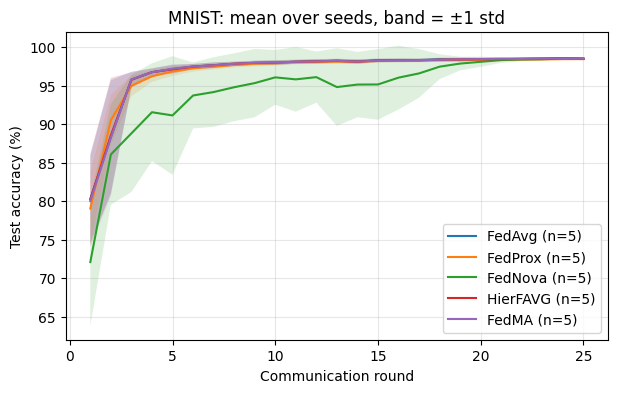

In [10]:
import glob, json
import numpy as np, pandas as pd
import matplotlib.pyplot as plt

DS = 'MNIST'
runs = [json.load(open(f)) for f in glob.glob(f'{RESULTS}/main/*.json')]
runs = [r for r in runs if r['dataset'] == DS]
if not runs:
    print('no main runs for', DS, 'yet')
else:
    df = pd.DataFrame([dict(algorithm=r['algorithm'], seed=r['seed'],
                            final=r['history']['accuracy'][-1], best=max(r['history']['accuracy']),
                            wan_MiB=r['history']['wan_comm_mb'][-1]) for r in runs])
    order = ['FedAvg', 'FedProx', 'FedNova', 'HierFAVG', 'FedMA']
    table = (df.groupby('algorithm')
               .agg(seeds=('seed', 'count'), final_mean=('final', 'mean'), final_std=('final', 'std'),
                    best_mean=('best', 'mean'), wan_MiB=('wan_MiB', 'first'))
               .reindex([a for a in order if a in set(df.algorithm)]).round(2))
    display(table)

    fig, ax = plt.subplots(figsize=(7, 4))
    for a in table.index:
        A = np.array([r['history']['accuracy'] for r in runs if r['algorithm'] == a])
        x = np.arange(1, A.shape[1] + 1)
        ax.plot(x, A.mean(0), label=f'{a} (n={len(A)})')
        if len(A) > 1:
            ax.fill_between(x, A.mean(0) - A.std(0, ddof=1), A.mean(0) + A.std(0, ddof=1), alpha=0.15)
    ax.set_xlabel('Communication round'); ax.set_ylabel('Test accuracy (%)')
    ax.set_title(f'{DS}: mean over seeds, band = ±1 std'); ax.grid(alpha=0.3); ax.legend()
    plt.show()

## 7. Pack this dataset's logs into results_mnist.zip (send this file back)

In [11]:
zip_path = 'results_mnist.zip'
with zipfile.ZipFile(zip_path, 'w', zipfile.ZIP_DEFLATED) as z:
    for stage in ('main', 'sweep', 'ablation'):
        for f in sorted(glob.glob(os.path.join(RESULTS, stage, 'mnist_*.json'))):
            z.write(f, os.path.relpath(f, RESULTS))
print(zip_path, len(zipfile.ZipFile(zip_path).namelist()), 'run logs,', os.path.getsize(zip_path) // 1024, 'KB')
try:                                  # on Colab, also start a browser download
    from google.colab import files
    files.download(zip_path)
except ImportError:
    print('saved at', os.path.abspath(zip_path))

results_mnist.zip 45 run logs, 216 KB


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>